# Node Strength Centrality Jaccard Index on Binary Networks (GCC Adaptive Thresholding)

This notebook implements an identical workflow to `weighted/nodeStrengthJaccard.ipynb`, but converts the continuous segment-wise Pearson correlation networks into **binary adjacency matrices** using **GCC Adaptive Thresholding** before computing node strength centrality and evaluating inter-subject Jaccard similarity.

In a binary unweighted network, **Node Strength** directly corresponds to **Node Degree**—the sum of binary connections incident to each electrode ($k_i = \sum_j a_{ij}$).

### Thresholding Strategy: GCC Adaptive Binarization
For each segment matrix, we start at an initial threshold of `1.0` and step down by `0.05` until the **Giant Connected Component (GCC)** encompasses 100% of the nodes (`gcc_ratio == 1.0`). At that exact threshold, edges $\ge$ threshold become `1.0` and edges $<$ threshold become `0.0`.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import networkx as nx
import seaborn as sns
import matplotlib.pyplot as plt
from itertools import combinations

# Robust data directory resolution (handling execution both inside root and inside 'binary/' folder)
abs_segment_base = Path('../correlation_matrices_segment_wise_absolute')
if not abs_segment_base.exists():
    abs_segment_base = Path('correlation_matrices_segment_wise_absolute')
    
matrix_files = list(abs_segment_base.rglob('*.csv'))
if matrix_files:
    sample = pd.read_csv(matrix_files[0], index_col=0)
    print(f"Found {len(matrix_files)} matrix files. Sample shape: {sample.shape}")

# 1. GCC-Adaptive Binary Network Helper
def gcc_ratio(adj):
    G = nx.from_numpy_array(adj)
    if G.number_of_nodes() == 0:
        return 0.0
    comps = list(nx.connected_components(G))
    return max(len(c) for c in comps) / G.number_of_nodes()

def build_binary_network(df, step=0.05):
    abs_corr = np.abs(df.values)
    np.fill_diagonal(abs_corr, 0)

    thr = 1.0
    while thr >= 0.0:
        adj = (abs_corr >= thr).astype(float)
        np.fill_diagonal(adj, 0)
        if gcc_ratio(adj) == 1.0:
            return pd.DataFrame(adj, index=df.index, columns=df.columns), round(thr, 10)
        thr -= step
    # Fallback to fully connected without self loops if needed
    fallback = np.ones_like(abs_corr) - np.eye(df.shape[0])
    return pd.DataFrame(fallback, index=df.index, columns=df.columns), 0.0

# Test binarization on the sample matrix
binary_sample, used_thr = build_binary_network(sample)
print(f"Sample matrix binarized successfully at threshold: {used_thr}")

Found 2632 matrix files. Sample shape: (19, 19)
Sample matrix binarized successfully at threshold: 0.45


## Filter Subjects and Calculate Binary Node Strength Centrality

We filter the exact 20 study subjects and process the first 12 segments for session 1 (`ses-1`). Each individual segment matrix is dynamically converted into an unweighted binary graph using GCC adaptive thresholding, and we calculate **node strength centrality** (`G.degree(node, weight='weight')`) for each segment.

In [2]:
# Filter subjects
subject_ids = [64, 65, 69, 70, 75, 77, 78, 79, 80, 81, 82, 83, 84, 86, 87, 89, 90, 94, 96, 103]
formatted_subjects = [f"sub-NORB{sid:05d}" for sid in subject_ids]

n_segments = 12
subject_segment_ns = {}
subject_node_strength = {}
threshold_tracker = []

for subj in formatted_subjects:
    subj_dir = abs_segment_base / subj / "ses-1"
    if not subj_dir.exists():
        print(f"Warning: directory not found for {subj}")
        continue
        
    csv_files = sorted(subj_dir.glob('*.csv'))
    if len(csv_files) < n_segments:
        print(f"Warning: {subj} has less than {n_segments} segments")
        
    seg_ns_list = []
    for csv_file in csv_files[:n_segments]:
        df = pd.read_csv(csv_file, index_col=0)
        bin_df, thr = build_binary_network(df)
        threshold_tracker.append(thr)
        
        # Construct graph directly from binarized adjacency matrix
        G = nx.from_pandas_adjacency(bin_df)
        
        # Calculate node strength centrality for binary network
        ns = {node: G.degree(node, weight='weight') for node in G.nodes()}
        seg_ns_list.append(ns)
        
    if seg_ns_list:
        subject_segment_ns[subj] = seg_ns_list
        # Average node strength across the 12 segments for overall subject visualization
        all_nodes = list(seg_ns_list[0].keys())
        avg_ns = {n: np.mean([s[n] for s in seg_ns_list]) for n in all_nodes}
        subject_node_strength[subj] = avg_ns
        
print(f"Processed node strength across {n_segments} segments for {len(subject_node_strength)} subjects.")
print(f"Adaptive GCC Threshold Stats --> Min: {min(threshold_tracker):.2f}, Max: {max(threshold_tracker):.2f}, Mean: {np.mean(threshold_tracker):.2f}")

Processed node strength across 12 segments for 20 subjects.
Adaptive GCC Threshold Stats --> Min: 0.25, Max: 0.90, Mean: 0.52


## Plotting Averaged Binary Node Strength Centrality across Subjects (Sorted by Age Descending)

We arrange all 19 EEG electrodes strictly in anatomical order on the x-axis:
**Frontal (`F`)**, **Central (`C`)**, **Temporal (`T`)**, **Parietal (`P`)**, and **Occipital (`O`)**.

On the y-axis, we list all subjects sorted in descending order of age (oldest on top, youngest on the bottom).

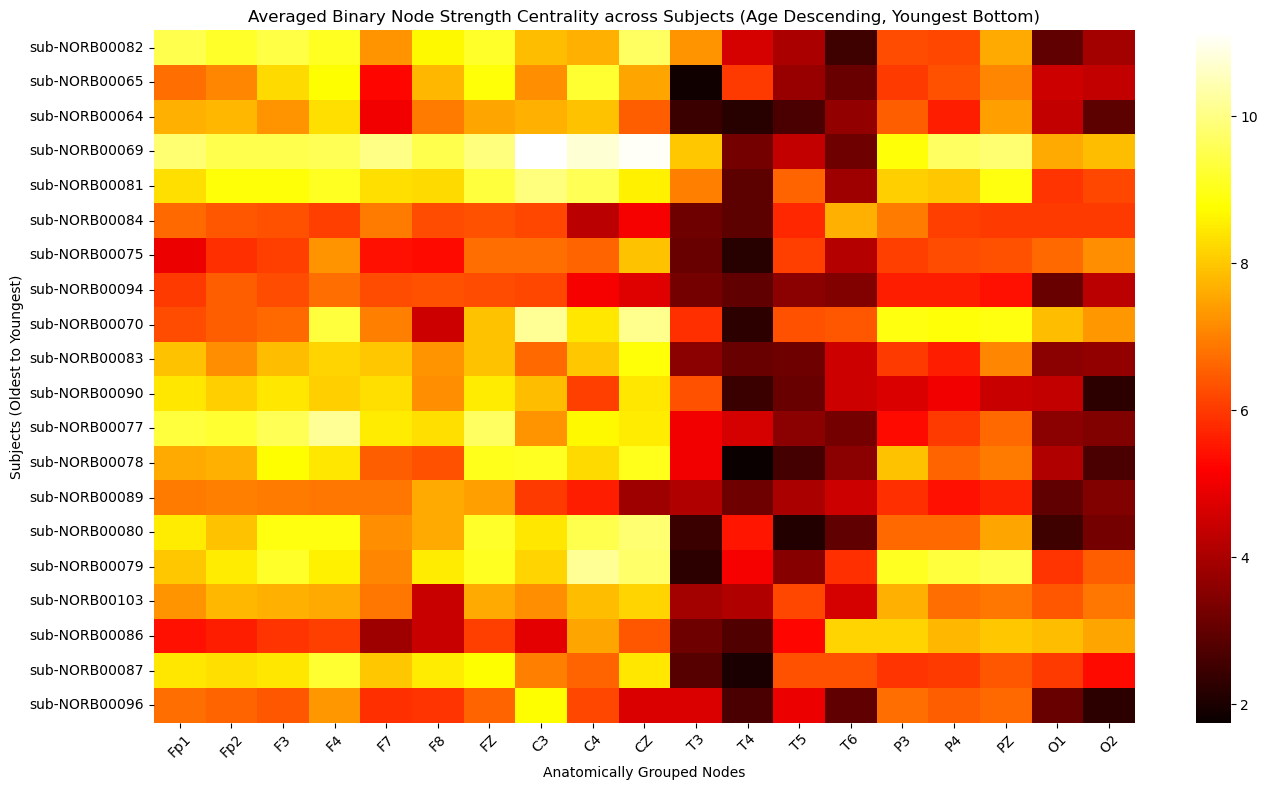

In [3]:
node_labels = [
    'Fp1', 'Fp2', 'F3', 'F4', 'F7', 'F8', 'FZ', 
    'C3', 'C4', 'CZ', 
    'T3', 'T4', 'T5', 'T6', 
    'P3', 'P4', 'PZ', 
    'O1', 'O2'
]

# Load ages and sort subjects descending (oldest top, youngest bottom)
age_csv = Path('../age_acq_time_sorted.csv')
if not age_csv.exists():
    age_csv = Path('age_acq_time_sorted.csv')
    
ages_df = pd.read_csv(age_csv)
target_labels = [f"{subj}_ses-1" for subj in formatted_subjects]
ages_filtered = ages_df[ages_df['label'].isin(target_labels)].copy()
ages_filtered = ages_filtered.sort_values('age_acq_time', ascending=False)

sorted_subject_labels = ages_filtered['label'].tolist()
sorted_subjects = [label.split('_')[0] for label in sorted_subject_labels]

# Prepare data for heatmap
raw_heatmap_data = []
valid_subjects = []

for subj in sorted_subjects:
    if subj in subject_node_strength:
        ns_dict = subject_node_strength[subj]
        row_data = [ns_dict.get(n, 0.0) for n in node_labels]
        raw_heatmap_data.append(row_data)
        valid_subjects.append(subj)

raw_heatmap_data = np.array(raw_heatmap_data)

# Plot heatmap
plt.figure(figsize=(14, 8))
sns.heatmap(raw_heatmap_data, cmap='hot', xticklabels=node_labels, yticklabels=valid_subjects)
plt.title('Averaged Binary Node Strength Centrality across Subjects (Age Descending, Youngest Bottom)')
plt.xlabel('Anatomically Grouped Nodes')
plt.ylabel('Subjects (Oldest to Youngest)')
plt.xticks(rotation=45, fontsize=10)
plt.tight_layout()
plt.show()

## Node-Wise Binary Strength Centrality Jaccard Index Calculation

For each of the 190 pairs of subjects (`20C2`), we compute the node-wise Jaccard similarity of strength centrality across corresponding time segments:
1. For each of the 12 segments ($s = 0 \dots 11$), we take the binary node strength scores $val_A$ and $val_B$ for each electrode.
2. We calculate the Jaccard similarity score per node: $\text{Jaccard}_s = \frac{\min(val_A, val_B)}{\max(val_A, val_B)}$ (if $\max(val_A, val_B) > 0$, else $0$).
3. We **average across these 12 time segments** ($\frac{1}{12}\sum_{s=0}^{11} \text{Jaccard}_s$) to obtain a consistent, stable similarity profile containing exactly 19 node values per subject pair.

In [4]:
sample_subj = valid_subjects[0]
nodes_list = list(subject_segment_ns[sample_subj][0].keys())

pair_jaccard_all_nodes = {}

# Iterate over all 20C2 pairs
for subj_A, subj_B in combinations(valid_subjects, 2):
    node_jaccards = []

    for n in node_labels:
        segment_jaccards = []

        for s in range(n_segments):
            if s < len(subject_segment_ns[subj_A]) and s < len(subject_segment_ns[subj_B]):
                val_A = subject_segment_ns[subj_A][s].get(n, 0.0)
                val_B = subject_segment_ns[subj_B][s].get(n, 0.0)

                if max(val_A, val_B) > 0:
                    jaccard_s = min(val_A, val_B) / max(val_A, val_B)
                else:
                    jaccard_s = 0.0
                segment_jaccards.append(jaccard_s)

        # Averaging across the 12 time segments for temporal stability
        node_jaccards.append(np.mean(segment_jaccards) if segment_jaccards else 0.0)

    pair_jaccard_all_nodes[(subj_A, subj_B)] = node_jaccards

print(f"Calculated binary node strength centrality Jaccard indices for all {len(pair_jaccard_all_nodes)} subject pairs.")
print(f"Each pair vector contains exactly {len(list(pair_jaccard_all_nodes.values())[0])} electrode values.")

Calculated binary node strength centrality Jaccard indices for all 190 subject pairs.
Each pair vector contains exactly 19 electrode values.


## Plot Binary Node Strength Centrality Jaccard Index Heatmap (Sorted by Age Difference)

We arrange the subject pairs on the y-axis in descending order of their absolute age difference (largest age difference at the top, smallest at the bottom) and plot the horizontal heatmap.

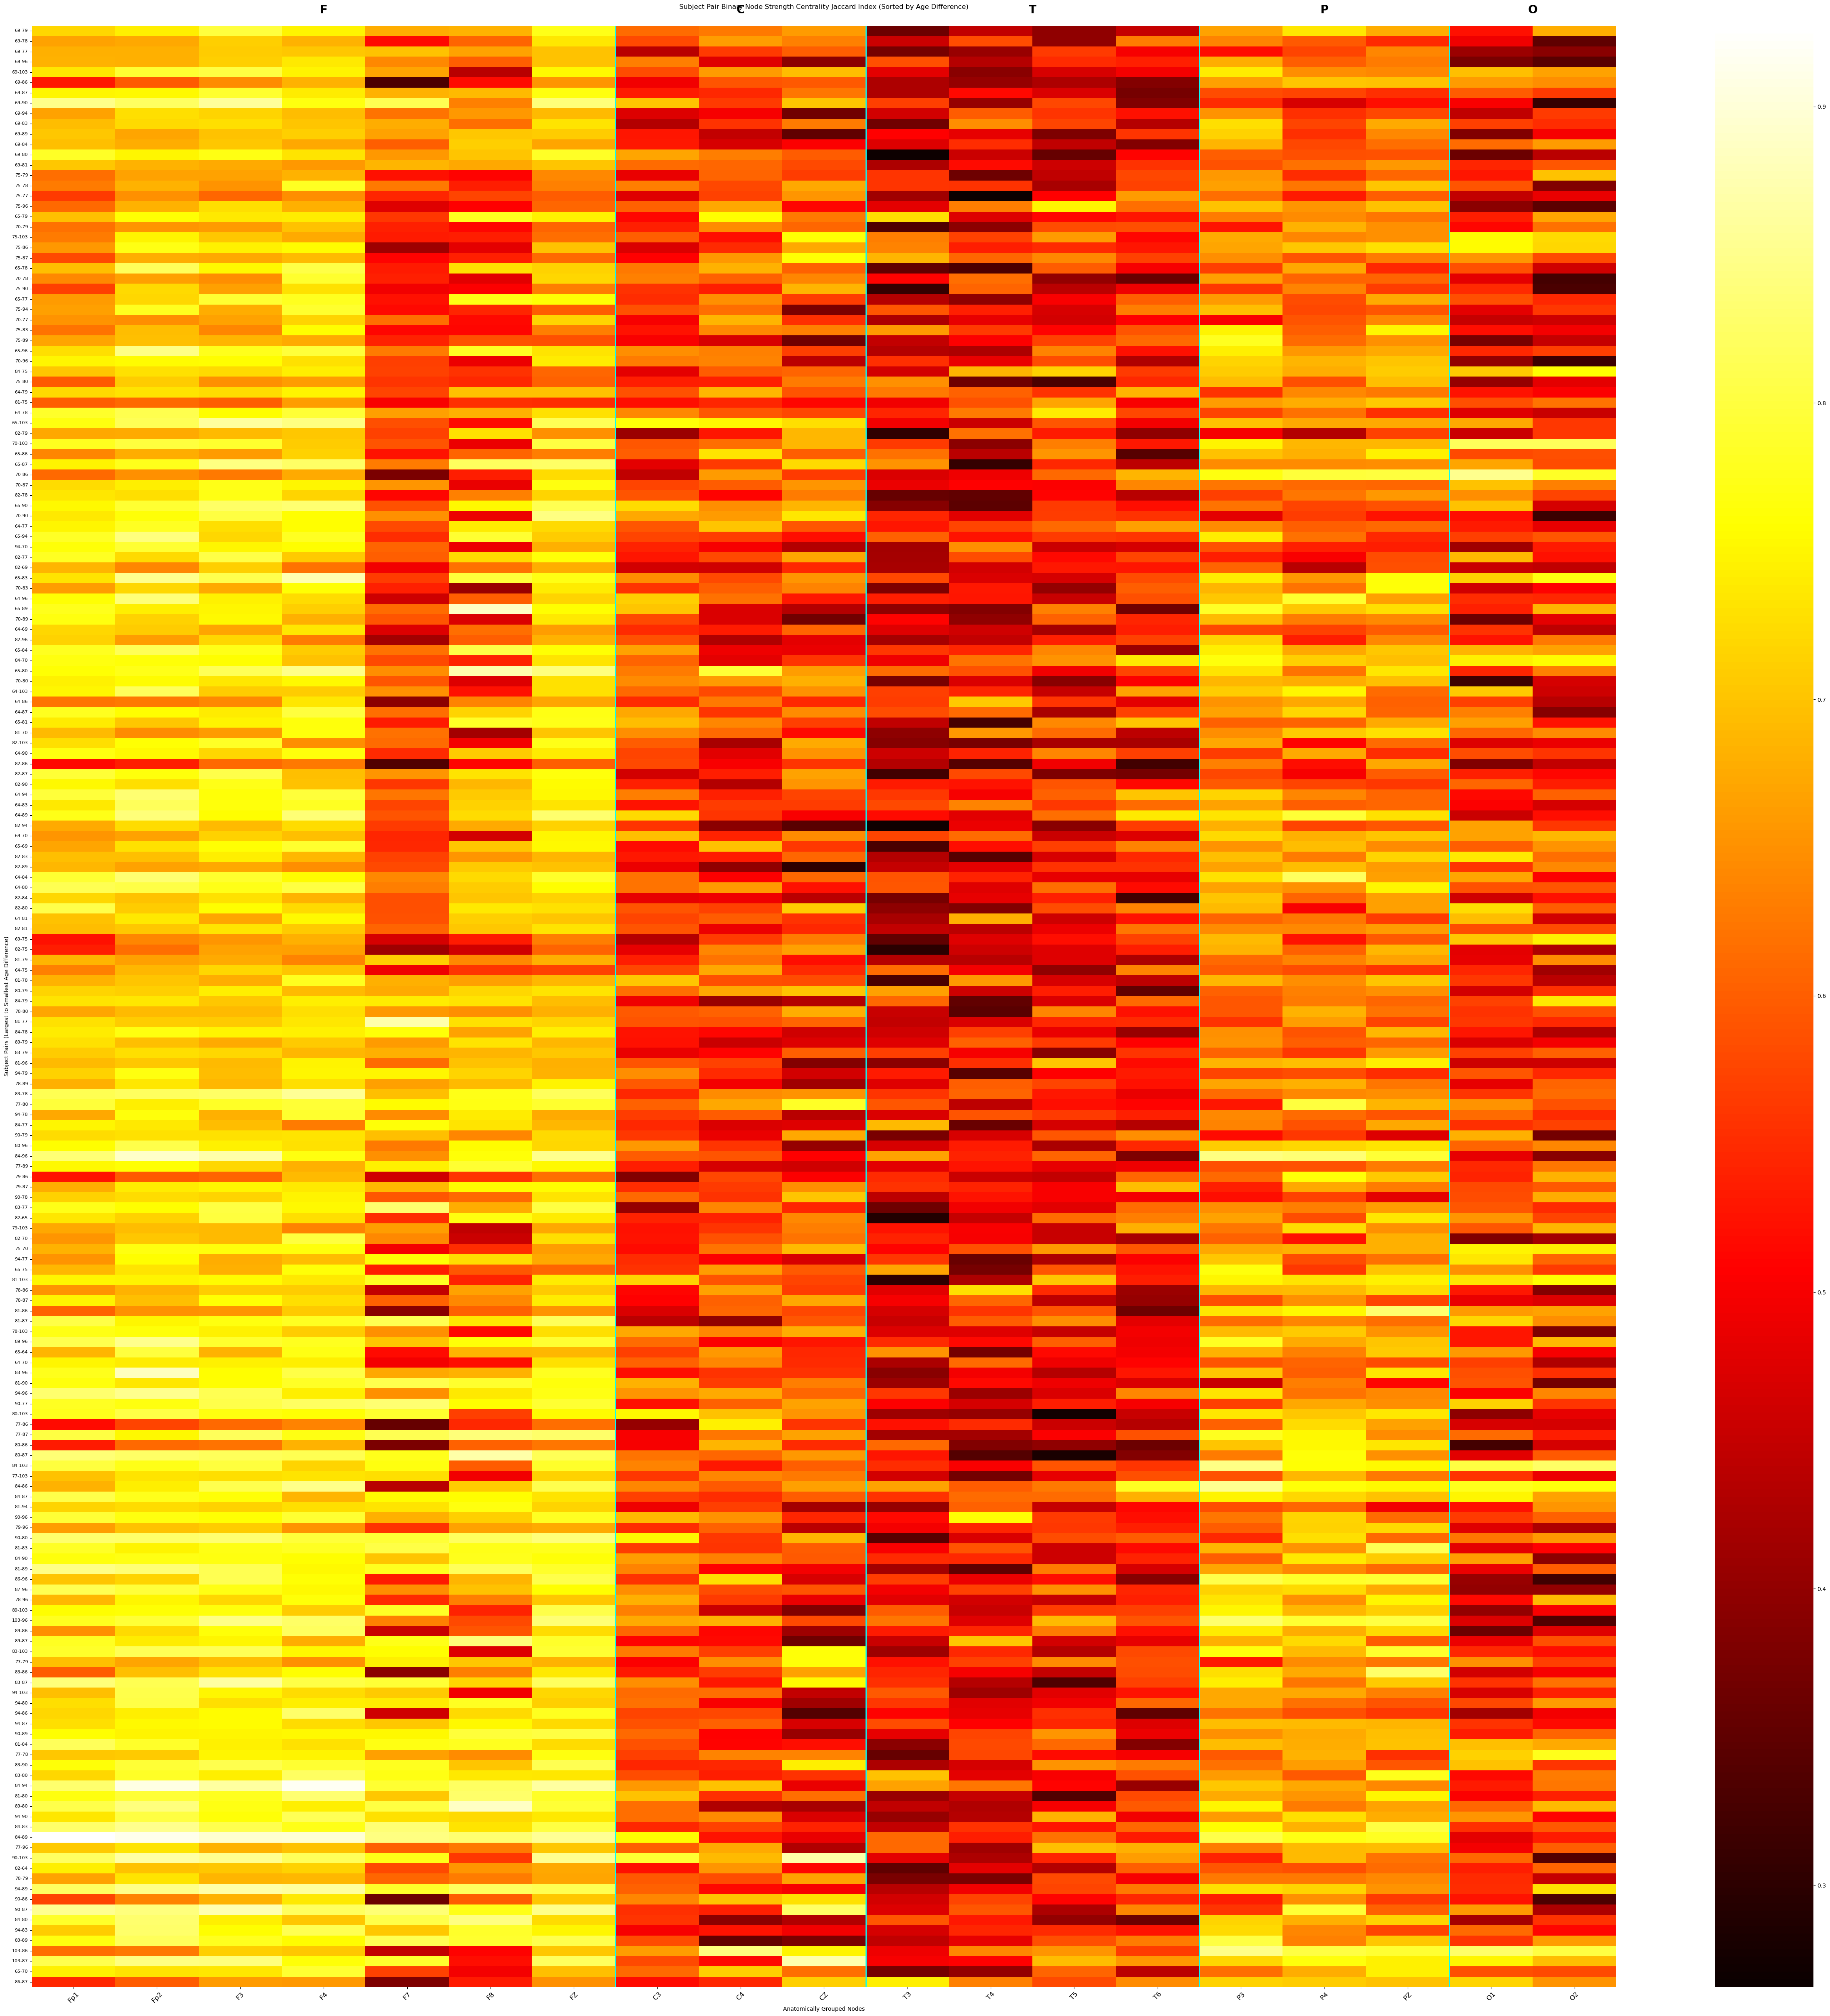

In [5]:
age_dict = {}
for idx, row in ages_df.iterrows():
    subj = row['label'].split('_')[0]
    age_dict[subj] = row['age_acq_time']

pair_age_diff = {}
for pair in pair_jaccard_all_nodes.keys():
    subj_A, subj_B = pair
    diff = abs(age_dict[subj_A] - age_dict[subj_B])
    pair_age_diff[pair] = diff

# Sort pairs by age difference descending (largest diff at top, smallest diff at bottom)
sorted_pairs = sorted(pair_age_diff.keys(), key=lambda x: pair_age_diff[x], reverse=True)

heatmap_data = []
yticklabels = []

for pair in sorted_pairs:
    p0 = str(int(pair[0].replace('sub-NORB', '')))
    p1 = str(int(pair[1].replace('sub-NORB', '')))
    yticklabels.append(f"{p0}-{p1}")
    heatmap_data.append(pair_jaccard_all_nodes[pair])

heatmap_data = np.array(heatmap_data)

# Plot heatmap
plt.figure(figsize=(50, 50))
sns.heatmap(heatmap_data, cmap='hot', xticklabels=node_labels, yticklabels=yticklabels)

# add label above each lobe
import matplotlib.transforms as transforms

ax = plt.gca()
trans = transforms.blended_transform_factory(ax.transData, ax.transAxes)

# Define each lobe label and its ending column index based on node_labels
# F: 7 nodes (0-6), C: 3 nodes (7-9), T: 4 nodes (10-13), P: 3 nodes (14-16), O: 2 nodes (17-18)
lobes = [
    ('F', 7),
    ('C', 10),
    ('T', 14),
    ('P', 17),
    ('O', 19)
]

start_idx = 0
for label, end_idx in lobes:
    # Draw vertical cyan dashed boundary line between lobes (except at the very right edge)
    if end_idx < 19:
        ax.axvline(x=end_idx, color='cyan', linewidth=2)
        
    # Add lobe label centered above its respective section at the top of the plot
    mid_x = (start_idx + end_idx) / 2.0
    ax.text(mid_x, 1.005, label, transform=trans, ha='center', va='bottom', fontsize=20, fontweight='bold')
    
    start_idx = end_idx


plt.title('Subject Pair Binary Node Strength Centrality Jaccard Index (Sorted by Age Difference)', pad=30)
plt.xlabel('Anatomically Grouped Nodes')
plt.ylabel('Subject Pairs (Largest to Smallest Age Difference)')
plt.xticks(rotation=45, fontsize=12)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

## Region-wise Statistical Summary of Binary Node Strength Jaccard Index

This cell calculates and displays a grouped bar plot showing the percentage of Binary Node Strength Jaccard index values exceeding **0.75** and **0.90** for each distinct brain region (**F**, **C**, **T**, **P**, and **O**).

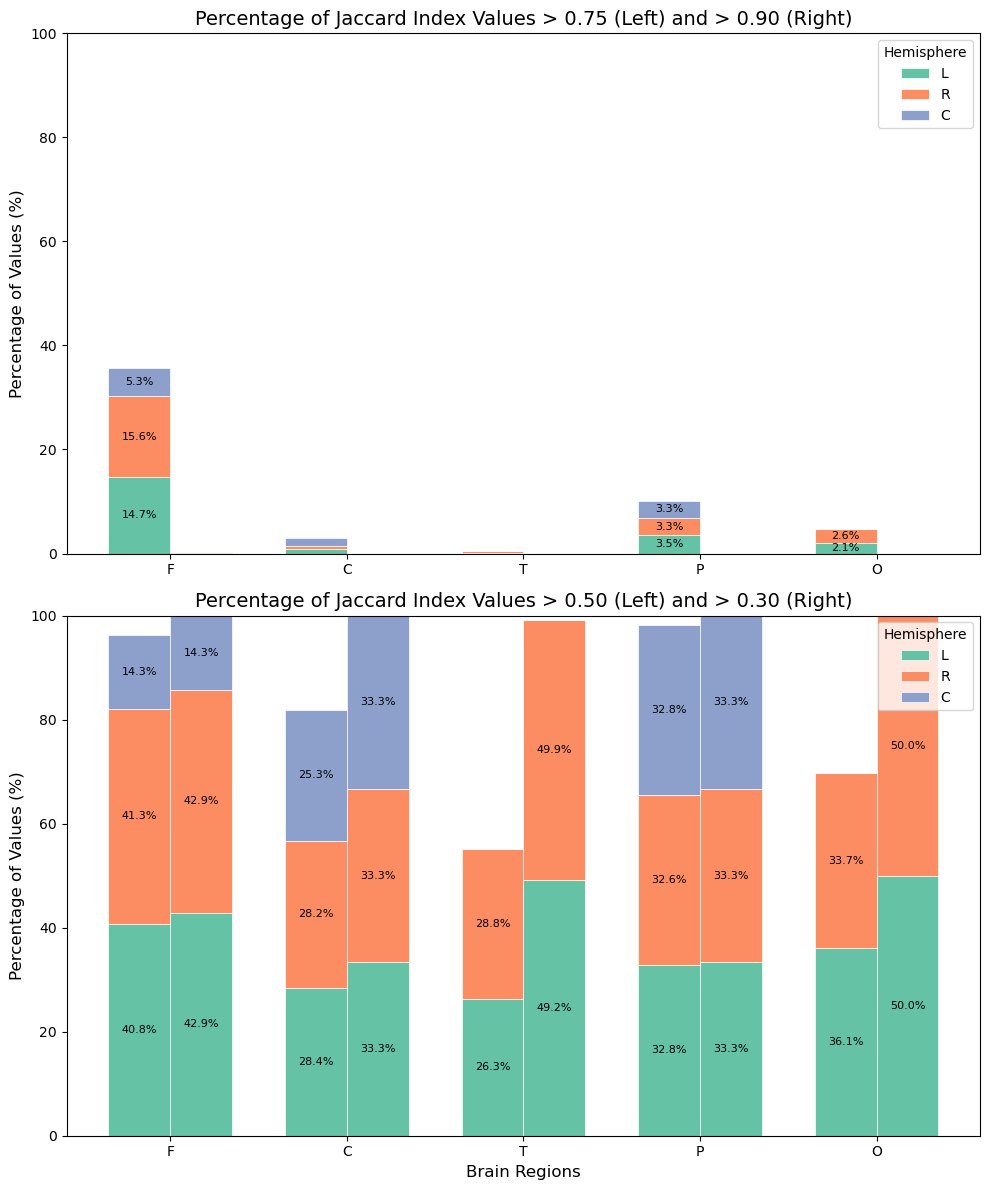

In [6]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# --- 1. Load Hemisphere Labels ---
labels_df = pd.read_csv('../electrode_labels.csv')
hemi_map = dict(zip(labels_df['channel'], labels_df['label']))

def get_hemi(node):
    return hemi_map.get(node, 'C')

# --- 2. Map every node to Region and Hemisphere ---
region_groups = ['F', 'C', 'T', 'P', 'O']
hemi_groups = ['L', 'R', 'C']

stats_data = []

for cat in region_groups:
    # Find all nodes belonging to this Region (F, C, T, P, O)
    node_indices = [idx for idx, n in enumerate(node_labels) if n[0].upper() == cat]
    
    total_vals_in_region = len(node_indices) * heatmap_data.shape[0]
    
    for hemi in hemi_groups:
        hemi_indices = [idx for idx in node_indices if get_hemi(node_labels[idx]) == hemi]
        
        if hemi_indices and total_vals_in_region > 0:
            vals = heatmap_data[:, hemi_indices].flatten()
            pct_30 = (np.sum(vals > 0.30) / total_vals_in_region) * 100.0
            pct_50 = (np.sum(vals > 0.50) / total_vals_in_region) * 100.0
            pct_75 = (np.sum(vals > 0.75) / total_vals_in_region) * 100.0
            pct_90 = (np.sum(vals > 0.90) / total_vals_in_region) * 100.0
        else:
            pct_30, pct_50, pct_75, pct_90 = 0.0, 0.0, 0.0, 0.0
            
        stats_data.append({'Brain Region': cat, 'Threshold': '> 0.30', 'Hemi': hemi, 'Percentage': pct_30})
        stats_data.append({'Brain Region': cat, 'Threshold': '> 0.50', 'Hemi': hemi, 'Percentage': pct_50})
        stats_data.append({'Brain Region': cat, 'Threshold': '> 0.75', 'Hemi': hemi, 'Percentage': pct_75})
        stats_data.append({'Brain Region': cat, 'Threshold': '> 0.90', 'Hemi': hemi, 'Percentage': pct_90})

df_stats = pd.DataFrame(stats_data)

# --- 4. Plot the Stacked Bar Charts ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 12))

colors = sns.color_palette("Set2", 3)
color_map = dict(zip(hemi_groups, colors))

x = np.arange(len(region_groups))
width = 0.35

def plot_grouped_stacked(ax, thresh1, thresh2, title):
    # thresh1
    df1 = df_stats[df_stats['Threshold'] == thresh1].pivot(index='Brain Region', columns='Hemi', values='Percentage')
    df1 = df1.reindex(index=region_groups, columns=hemi_groups).fillna(0)
    
    # thresh2
    df2 = df_stats[df_stats['Threshold'] == thresh2].pivot(index='Brain Region', columns='Hemi', values='Percentage')
    df2 = df2.reindex(index=region_groups, columns=hemi_groups).fillna(0)
    
    bottom1 = np.zeros(len(region_groups))
    bottom2 = np.zeros(len(region_groups))
    
    for hemi in hemi_groups:
        vals1 = df1[hemi].values
        vals2 = df2[hemi].values
        
        # Plot thresh1 on left
        bars1 = ax.bar(x - width/2, vals1, width, bottom=bottom1, label=hemi, color=color_map[hemi], edgecolor='white', linewidth=0.5)
        # Plot thresh2 on right (no label to avoid legend duplicates)
        bars2 = ax.bar(x + width/2, vals2, width, bottom=bottom2, color=color_map[hemi], edgecolor='white', linewidth=0.5)
        
        # Add labels
        ax.bar_label(bars1, labels=[f'{v:.1f}%' if v > 2 else '' for v in vals1], label_type='center', fontsize=8)
        ax.bar_label(bars2, labels=[f'{v:.1f}%' if v > 2 else '' for v in vals2], label_type='center', fontsize=8)
        
        bottom1 += vals1
        bottom2 += vals2

    ax.set_xticks(x)
    ax.set_xticklabels(region_groups)
    ax.set_title(title, fontsize=14)
    ax.set_ylabel('Percentage of Values (%)', fontsize=12)
    ax.set_ylim(0, 100)
    ax.legend(title='Hemisphere', loc='upper right')

# --- Plot 1: > 0.75 and > 0.90 ---
plot_grouped_stacked(ax1, '> 0.75', '> 0.90', 'Percentage of Jaccard Index Values > 0.75 (Left) and > 0.90 (Right)')

# --- Plot 2: > 0.50 and > 0.30 ---
plot_grouped_stacked(ax2, '> 0.50', '> 0.30', 'Percentage of Jaccard Index Values > 0.50 (Left) and > 0.30 (Right)')

ax2.set_xlabel('Brain Regions', fontsize=12)

plt.tight_layout()
plt.show()
